# 02 · Frequency response

A sinusoidal input to a stable linear system produces, after transients, a sinusoidal output of the same
frequency scaled by |G(jω)| and shifted by ∠G(jω). The function G(jω) - the frequency response - can be
measured on a real plant, plotted on Bode's logarithmic axes where products become sums, and read for stability
margins and bandwidth. This notebook establishes the sinusoidal steady state by simulation, builds Bode plots
from asymptotes, shows the Nyquist and Nichols representations, and computes the margins that the design
chapters will use.

**What you will learn**
- establish the sinusoidal steady state and compute G(jw)
- sketch Bode plots from asymptotes and read corners, slopes and phases
- interpret Nyquist and Nichols plots
- compute gain, phase and delay margins, bandwidth and resonant peak

**Before you start:** notebooks 00 and 01  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, frequency as fr, response as rs, models
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The sinusoidal steady state

In [2]:
G = sy.tf([4.0], [1.0, 1.2, 4.0])
w = 3.0
t = np.linspace(0, 40, 16001)
_, y, _ = rs.lsim(G, np.sin(w * t), t)
tail = t > 30
M = np.column_stack([np.sin(w * t[tail]), np.cos(w * t[tail])])
a, b = np.linalg.lstsq(M, y[tail], rcond=None)[0]
print(f"simulated steady state: amplitude {np.hypot(a, b):.5f}, phase {np.degrees(np.arctan2(b, a)):.3f} deg")
Gjw = fr.freqresp(G, w)
print(f"G(3j) = {Gjw:.5f}: |G| = {abs(Gjw):.5f}, arg G = {np.degrees(np.angle(Gjw)):.3f} deg  (the simulation's phase also carries the half-sample delay of the zero-order hold, -w h/2 = {np.degrees(-w * (t[1] - t[0]) / 2):.3f} deg)")

simulated steady state: amplitude 0.64923, phase -144.461 deg
G(3j) = -0.52687-0.37935j: |G| = 0.64923, arg G = -144.246 deg  (the simulation's phase also carries the half-sample delay of the zero-order hold, -w h/2 = -0.215 deg)


The simulation agrees with G(jω) to the fifth digit in amplitude; the phase differs by exactly the half-sample
delay the zero-order hold imposes on the simulated input (notebook 12). G(jω) is the transfer function
evaluated on the imaginary axis - nothing more - and yet it contains the whole input-output behaviour.

## Bode plots from asymptotes

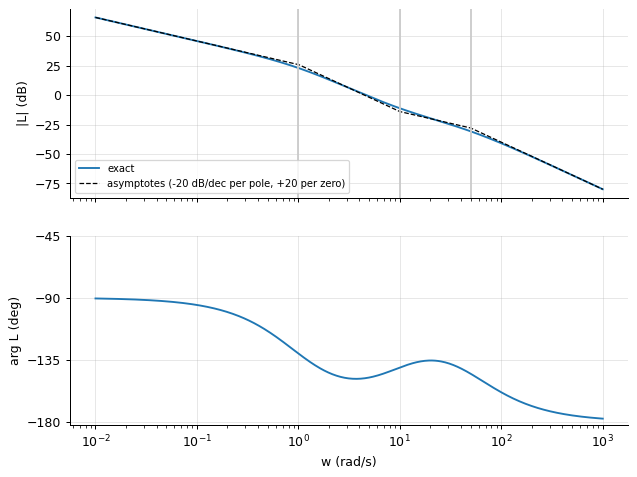

largest error of the straight-line asymptotes: 2.93 dB (3 dB at a real pole or zero's corner, as the theory says)


In [3]:
L = sy.zpk([-10.0], [0.0, -1.0, -50.0], 100.0)          # 100 (s + 10) / (s (s + 1)(s + 50))
w = np.logspace(-2, 3, 500)
w_, mag, ph = fr.bode(L, w)
asym = 20 * np.log10(100 * 10 / 50) - 20 * np.log10(w)                                  # low-frequency: integrator with gain K = 100*10/50
asym = asym - 20 * np.log10(np.maximum(w / 1.0, 1)) + 20 * np.log10(np.maximum(w / 10.0, 1)) - 20 * np.log10(np.maximum(w / 50.0, 1))
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].semilogx(w, mag, label="exact"); axes[0].semilogx(w, asym, "k--", lw=1, label="asymptotes (-20 dB/dec per pole, +20 per zero)"); axes[0].set_ylabel("|L| (dB)"); axes[0].legend(fontsize=8)
for c, lab in ((1, "pole"), (10, "zero"), (50, "pole")):
    axes[0].axvline(c, color="0.8")
axes[1].semilogx(w, ph); axes[1].set_ylabel("arg L (deg)"); axes[1].set_xlabel("w (rad/s)"); axes[1].set_yticks([-180, -135, -90, -45])
plt.show()
print(f"largest error of the straight-line asymptotes: {np.max(np.abs(mag - asym)):.2f} dB (3 dB at a real pole or zero's corner, as the theory says)")

On logarithmic axes each factor of the transfer function contributes additively: an integrator a −20 dB/decade
line through 0 dB at ω = K, each real pole a corner that bends the slope down by 20 dB/decade, each zero one
that bends it up, and each corner shifts the phase by 90° spread over two decades. The straight-line
asymptotes miss the exact curve by at most 3 dB at a corner (6 dB for a double pole, more for an underdamped
pair whose peak is 1/(2ζ)). Sketching them is still the quickest way to see what a controller will do.

## Nyquist and Nichols

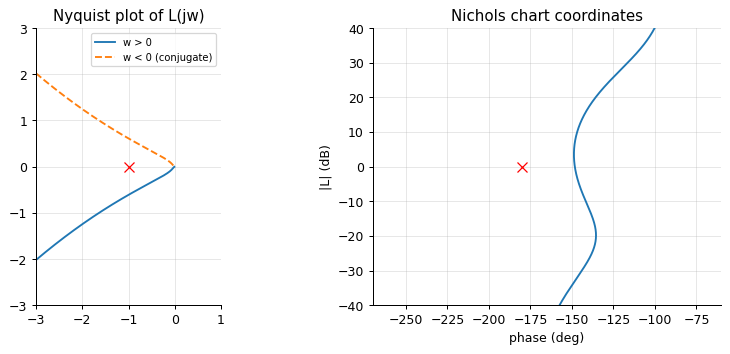

In [4]:
w = np.logspace(-2, 2, 2000)
_, Lj = fr.nyquist(L, w)
ph_n, mag_n = fr.nichols(L, w)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(Lj.real, Lj.imag, label="w > 0"); axes[0].plot(Lj.real, -Lj.imag, "--", label="w < 0 (conjugate)"); axes[0].plot(-1, 0, "rx", ms=8)
axes[0].set_xlim(-3, 1); axes[0].set_ylim(-3, 3); axes[0].set_aspect("equal"); axes[0].legend(fontsize=8); axes[0].set_title("Nyquist plot of L(jw)")
axes[1].plot(ph_n, mag_n); axes[1].plot(-180, 0, "rx", ms=8); axes[1].set_xlabel("phase (deg)"); axes[1].set_ylabel("|L| (dB)"); axes[1].set_title("Nichols chart coordinates"); axes[1].set_xlim(-270, -60); axes[1].set_ylim(-40, 40)
plt.show()

The Nyquist plot draws G(jω) in the complex plane as ω runs from −∞ to ∞ (the negative half is the mirror
image); the point −1 is where the loop gain would make 1 + L = 0 and the closed loop sing. The Nichols chart
plots the same curve as magnitude in dB against phase, where the critical point is (−180°, 0 dB) and the
closed-loop magnitude can be read from overlaid contours. All three plots carry the same information; Bode is
best for design, Nyquist for stability proofs, Nichols for closed-loop peaks.

## Margins, bandwidth and resonance

In [5]:
m = fr.margins(L)
print(f"gain margin {m['gain_margin']:.3f} ({m['gain_margin_db']:.1f} dB) at the phase crossover w = {m['w_pc']:.3f} rad/s")
print(f"phase margin {m['phase_margin']:.1f} deg at the gain crossover w = {m['w_gc']:.3f} rad/s; delay margin {m['delay_margin'] * 1000:.0f} ms")
T = sy.feedback(L)
print(f"closed loop: -3 dB bandwidth {fr.bandwidth(T):.3f} rad/s (about the gain crossover), resonant peak {fr.resonant_peak(T)[0]:.3f} at {fr.resonant_peak(T)[1]:.3f} rad/s")
L2 = sy.tf([10.0], [1.0, 3.0, 2.0, 0.0])
m2 = fr.margins(L2)
print(f"\n10/(s(s+1)(s+2)): gain margin {m2['gain_margin']:.2f} < 1 and phase margin {m2['phase_margin']:.1f} deg < 0 -> the closed loop is unstable (poles {np.round(sy.feedback(L2).poles(), 3)})")

gain margin inf (inf dB) at the phase crossover w = nan rad/s
phase margin 31.7 deg at the gain crossover w = 4.632 rad/s; delay margin 120 ms
closed loop: -3 dB bandwidth 7.117 rad/s (about the gain crossover), resonant peak 1.920 at 4.203 rad/s

10/(s(s+1)(s+2)): gain margin 0.60 < 1 and phase margin -13.0 deg < 0 -> the closed loop is unstable (poles [-3.309+0.j     0.154+1.732j  0.154-1.732j])


The gain margin is how much the loop gain can grow before the Nyquist curve passes through −1 (read at the
phase crossover, where the phase is −180°); the phase margin is how much phase lag can be added before it does
(read at the gain crossover, where |L| = 1); the delay margin converts the phase margin into a time, the delay
that would destabilise the loop. The library finds every crossing and reports the critical ones. The example
loop has an *infinite* gain margin - its phase approaches −180° from above and never crosses - yet it is not a
robust loop: a phase margin of 32° and a resonant peak of 1.9 say so, and 120 ms of delay would destabilise it.
One margin never tells the whole story. For 10/(s(s+1)(s+2)) both margins are negative and the closed loop
is indeed unstable; for a well-designed loop 45-60° and 2-3 (6-10 dB) are the usual targets. The closed-loop
bandwidth is close to the gain crossover frequency, and the resonant peak grows as the margins shrink - the
frequency-domain face of overshoot.

## Inside the algorithm: finding a gain crossover by bisection

In [6]:
f = lambda w_: np.log10(abs(fr.freqresp(L, w_)))     # noqa: E731
a, b = 0.1, 100.0
for _ in range(60):
    m_ = np.sqrt(a * b)
    if f(a) * f(m_) <= 0: b = m_
    else: a = m_
print(f"gain crossover by bisection: {a:.6f} rad/s; library: {fr.margins(L)['w_gc']:.6f}")

gain crossover by bisection: 4.631723 rad/s; library: 4.631723


## Exercises
1. Add a pure delay of 0.1 s to L (`fr.freqresp(L, w, delay=0.1)` and `fr.margins(L, delay=0.1)`): how do the margins change, and does the gain margin or the phase margin react first? Compare with the delay margin computed before.
2. Sketch by hand the Bode asymptotes of the DC motor's voltage-to-speed transfer function and check them against `fr.bode`. Where is its bandwidth, and what sets it?
3. **Implement it yourself:** compute the Nyquist curve of L from the state-space model with C (jwI - A)^-1 B + D (one linear solve per frequency) and compare with the transfer-function evaluation; which is better conditioned for a 10th-order system?